# StyleGAN — A Style-Based Generator Architecture for Generative Adversarial Networks

**Paper:** Karras, Laine, Aila (2019) — [arXiv:1812.04948](https://arxiv.org/abs/1812.04948)

This notebook implements a miniature StyleGAN with:
- Mapping network (8-layer MLP: z → w)
- AdaIN-based style injection at each generator layer
- Learned constant input (instead of feeding z into the first layer)
- Stochastic noise injection after each convolution
- Style mixing regularization and visualization

It is scaled down to 32×32 images of synthetic colored shapes, so it shows how the parts work, not the paper's image quality. The Summary at the end says what this run produced.


## 1. Imports and Configuration

In [1]:
import atexit
import os
import shutil

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

# Config: small enough to train in minutes
LATENT_DIM = 128
W_DIM = 128
IMAGE_SIZE = 32
CHANNELS = 32         # feature maps in every synthesis block
BATCH_SIZE = 32
EPOCHS = 120          # 25 batches per epoch, so 3,000 training steps
LR = 1e-3
MAPPING_LR_SCALE = 0.01   # the paper lowers the mapping network's learning rate by 100x
MIXING_PROB = 0.9         # share of training batches that use style mixing (the paper's config F)
R1_GAMMA = 10.0

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")


Device: cuda


## 2. Toy Dataset (Synthetic Shapes)

In [2]:
# Use a small synthetic dataset of colored shapes — fast, no download needed
def make_synthetic_dataset(n=800, size=32):
    """Generate simple colored circles/squares on random backgrounds."""
    data = np.zeros((n, 3, size, size), dtype=np.float32)
    for i in range(n):
        bg = np.random.uniform(-0.8, 0.8, 3).reshape(3, 1, 1)
        data[i] = np.broadcast_to(bg, (3, size, size)).copy()
        # Draw a random circle or square
        cx, cy = np.random.randint(6, size-6, 2)
        r = np.random.randint(3, 8)
        color = np.random.uniform(-1, 1, 3)
        yy, xx = np.meshgrid(np.arange(size), np.arange(size), indexing='ij')
        if np.random.rand() > 0.5:
            mask = (xx - cx)**2 + (yy - cy)**2 < r**2
        else:
            mask = (np.abs(xx - cx) < r) & (np.abs(yy - cy) < r)
        for c in range(3):
            data[i, c][mask] = color[c]
    return torch.from_numpy(data)

dataset_tensor = make_synthetic_dataset(800, IMAGE_SIZE)
dataset = TensorDataset(dataset_tensor)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
print(f"Dataset size: {len(dataset)}, Batches: {len(dataloader)}")


Dataset size: 800, Batches: 25


## 3. Equalized Learning Rate Layers

In [3]:
class EqualizedConv2d(nn.Module):
    """Conv2d with equalized learning rate (from Progressive GAN)."""
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(out_ch, in_ch, kernel_size, kernel_size))
        self.bias = nn.Parameter(torch.zeros(out_ch))
        self.scale = (in_ch * kernel_size * kernel_size) ** -0.5
        self.stride = stride
        self.padding = padding

    def forward(self, x):
        return F.conv2d(x, self.weight * self.scale, self.bias, self.stride, self.padding)


class EqualizedLinear(nn.Module):
    """Linear with equalized learning rate."""
    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(out_features, in_features))
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.scale = (in_features) ** -0.5

    def forward(self, x):
        return F.linear(x, self.weight * self.scale, self.bias)


## 4. AdaIN (Adaptive Instance Normalization)

In [4]:
class AdaIN(nn.Module):
    """
    Adaptive Instance Normalization (Eq. 1 from the paper):
      AdaIN(x_i, y) = y_{s,i} * (x_i - mu(x_i)) / sigma(x_i) + y_{b,i}
    """
    def __init__(self, channels):
        super().__init__()
        self.channels = channels

    def forward(self, x, style):
        y_s = style[:, :self.channels, None, None]
        y_b = style[:, self.channels:, None, None]
        mean = x.mean(dim=[2, 3], keepdim=True)
        std = x.std(dim=[2, 3], keepdim=True) + 1e-8
        x_norm = (x - mean) / std
        return y_s * x_norm + y_b


## 5. Noise Injection

In [5]:
class NoiseInjection(nn.Module):
    """Adds single-channel Gaussian noise scaled by learned per-channel factor."""
    def __init__(self, channels):
        super().__init__()
        self.weight = nn.Parameter(torch.zeros(1, channels, 1, 1))

    def forward(self, x):
        # Fresh noise on every call, during training and when sampling, as in the paper
        noise = torch.randn(x.shape[0], 1, x.shape[2], x.shape[3], device=x.device)
        return x + self.weight * noise


## 6. Styled Convolution Block

In [6]:
class StyledConvBlock(nn.Module):
    """Two convolutions with noise injection and AdaIN style modulation."""
    def __init__(self, in_ch, out_ch, w_dim):
        super().__init__()
        self.conv1 = EqualizedConv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = EqualizedConv2d(out_ch, out_ch, 3, padding=1)
        self.noise1 = NoiseInjection(out_ch)
        self.noise2 = NoiseInjection(out_ch)
        self.adain1 = AdaIN(out_ch)
        self.adain2 = AdaIN(out_ch)
        self.style1 = EqualizedLinear(w_dim, 2 * out_ch)
        self.style2 = EqualizedLinear(w_dim, 2 * out_ch)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, w):
        x = self.conv1(x)
        x = self.noise1(x)
        x = self.act(x)
        x = self.adain1(x, self.style1(w))
        x = self.conv2(x)
        x = self.noise2(x)
        x = self.act(x)
        x = self.adain2(x, self.style2(w))
        return x


## 7. Mapping Network (z → w)

In [7]:
class MappingNetwork(nn.Module):
    """8-layer MLP mapping z to intermediate latent w."""
    def __init__(self, latent_dim=128, w_dim=128, n_layers=8):
        super().__init__()
        layers = []
        in_f = latent_dim
        for _ in range(n_layers):
            layers.append(EqualizedLinear(in_f, w_dim))
            layers.append(nn.LeakyReLU(0.2))
            in_f = w_dim
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


## 8. Synthesis Network (w → image)

In [8]:
class SynthesisNetwork(nn.Module):
    """Generates images from w. Starts from learned constant, progressively upsamples."""
    def __init__(self, w_dim=128, channels=8, target_size=32):
        super().__init__()
        self.channels = channels
        self.const_input = nn.Parameter(torch.ones(1, channels, 4, 4))
        self.blocks = nn.ModuleList()
        for _ in range(4):  # resolutions: 4, 8, 16, 32
            self.blocks.append(StyledConvBlock(channels, channels, w_dim))
        self.to_rgb = EqualizedConv2d(channels, 3, 1)

    def forward(self, w, crossover_w=None, crossover_idx=None):
        B = w.shape[0]
        x = self.const_input.expand(B, -1, -1, -1)
        for i, block in enumerate(self.blocks):
            if i > 0:
                x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
            style = w
            if crossover_w is not None and crossover_idx is not None and i >= crossover_idx:
                style = crossover_w
            x = block(x, style)
        return self.to_rgb(x)


## 9. StyleGAN Generator

In [9]:
class StyleGenerator(nn.Module):
    """Full StyleGAN generator: mapping + synthesis."""
    def __init__(self, latent_dim=128, w_dim=128, channels=8, target_size=32):
        super().__init__()
        self.mapping = MappingNetwork(latent_dim, w_dim)
        self.synthesis = SynthesisNetwork(w_dim, channels, target_size)

    def forward(self, z, z2=None, crossover_idx=None):
        w = self.mapping(z)
        w2 = self.mapping(z2) if z2 is not None else None
        return self.synthesis(w, crossover_w=w2, crossover_idx=crossover_idx)

    def generate(self, z, mixing_prob=0.0):
        if mixing_prob > 0 and np.random.rand() < mixing_prob:
            z2 = torch.randn_like(z)
            crossover_idx = np.random.randint(1, 4)
            return self(z, z2, crossover_idx)
        return self(z)


## 10. Discriminator

In [10]:
class Discriminator(nn.Module):
    """Standard discriminator (not modified per paper)."""
    def __init__(self, in_channels=3, channels=8):
        super().__init__()
        self.net = nn.Sequential(
            EqualizedConv2d(in_channels, channels, 4, 2, 1),
            nn.LeakyReLU(0.2),
            EqualizedConv2d(channels, channels * 2, 4, 2, 1),
            nn.LeakyReLU(0.2),
            EqualizedConv2d(channels * 2, channels * 4, 4, 2, 1),
            nn.LeakyReLU(0.2),
        )
        self.final = nn.Sequential(
            nn.Flatten(),
            EqualizedLinear(channels * 4 * 4 * 4, 1)
        )

    def forward(self, x):
        return self.final(self.net(x))


## 11. Initialize Models and Optimizers

In [11]:
G = StyleGenerator(LATENT_DIM, W_DIM, CHANNELS, IMAGE_SIZE).to(DEVICE)
D = Discriminator(3, CHANNELS).to(DEVICE)

G_no_map = [p for n, p in G.named_parameters() if not n.startswith('mapping')]
G_map = [p for n, p in G.named_parameters() if n.startswith('mapping')]

opt_G = optim.Adam([
    {'params': G_no_map, 'lr': LR},
    {'params': G_map, 'lr': LR * MAPPING_LR_SCALE},
], betas=(0.0, 0.99))
opt_D = optim.Adam(D.parameters(), lr=LR, betas=(0.0, 0.99))

# EMA of generator
ema_decay = 0.999
ema_G = StyleGenerator(LATENT_DIM, W_DIM, CHANNELS, IMAGE_SIZE).to(DEVICE)
ema_G.load_state_dict(G.state_dict())
for p in ema_G.parameters():
    p.requires_grad = False

print(f"Generator params: {sum(p.numel() for p in G.parameters()):,}")
print(f"Discriminator params: {sum(p.numel() for p in D.parameters()):,}")


Generator params: 272,995
Discriminator params: 167,649


## 12. Training Utilities

In [12]:
def requires_grad(model, flag=True):
    for p in model.parameters():
        p.requires_grad = flag

def r1_penalty(real_pred, real_img):
    grads = torch.autograd.grad(outputs=real_pred.sum(), inputs=real_img, create_graph=True)[0]
    return grads.pow(2).reshape(grads.shape[0], -1).mean()

def d_loss_fn(real_pred, fake_pred):
    return F.softplus(-real_pred).mean() + F.softplus(fake_pred).mean()

def g_loss_fn(fake_pred):
    return F.softplus(-fake_pred).mean()


## 13. Training Loop

In [13]:
G_losses, D_losses = [], []

for epoch in range(EPOCHS):
    for batch in dataloader:
        real_imgs = batch[0].to(DEVICE)
        B = real_imgs.shape[0]

        # ---- Train D ----
        requires_grad(D, True); requires_grad(G, False)
        opt_D.zero_grad()
        with torch.no_grad():
            z = torch.randn(B, LATENT_DIM, device=DEVICE)
            fake_imgs = G.generate(z, mixing_prob=MIXING_PROB)
        real_pred = D(real_imgs)
        fake_pred = D(fake_imgs.detach())
        d_loss = d_loss_fn(real_pred, fake_pred)
        real_imgs.requires_grad = True
        real_pred_r1 = D(real_imgs)
        r1 = r1_penalty(real_pred_r1, real_imgs)
        d_loss = d_loss + R1_GAMMA / 2 * r1
        d_loss.backward()
        opt_D.step()

        # ---- Train G ----
        requires_grad(D, False); requires_grad(G, True)
        opt_G.zero_grad()
        z = torch.randn(B, LATENT_DIM, device=DEVICE)
        fake_imgs = G.generate(z, mixing_prob=MIXING_PROB)
        fake_pred = D(fake_imgs)
        g_loss = g_loss_fn(fake_pred)
        g_loss.backward()
        opt_G.step()

        # EMA
        with torch.no_grad():
            for p_ema, p in zip(ema_G.parameters(), G.parameters()):
                p_ema.data.mul_(ema_decay).add_(p.data * (1 - ema_decay))

        G_losses.append(g_loss.item())
        D_losses.append(d_loss.item())

    if epoch == 0 or (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] | D: {np.mean(D_losses[-len(dataloader):]):.4f} | G: {np.mean(G_losses[-len(dataloader):]):.4f}")

print("Training complete!")


Epoch [1/120] | D: 1.3217 | G: 0.6824


Epoch [20/120] | D: 1.0326 | G: 0.9968


Epoch [40/120] | D: 0.7873 | G: 1.3702


Epoch [60/120] | D: 0.9935 | G: 1.2523


Epoch [80/120] | D: 1.1468 | G: 1.0132


Epoch [100/120] | D: 1.0284 | G: 1.0282


Epoch [120/120] | D: 1.3375 | G: 0.8562
Training complete!


## 14. Training Loss Curves

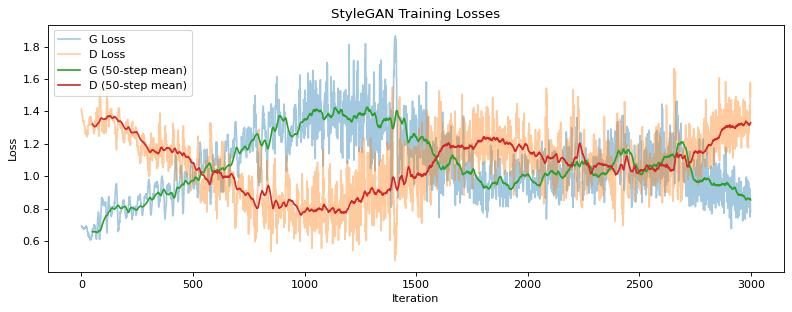

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(G_losses, label='G Loss', alpha=0.4)
plt.plot(D_losses, label='D Loss', alpha=0.4)
k = 50
plt.plot(np.arange(k - 1, len(G_losses)), np.convolve(G_losses, np.ones(k) / k, mode='valid'), label='G (50-step mean)')
plt.plot(np.arange(k - 1, len(D_losses)), np.convolve(D_losses, np.ones(k) / k, mode='valid'), label='D (50-step mean)')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('StyleGAN Training Losses')
plt.legend()
plt.tight_layout()
plt.savefig('loss_curves.png', dpi=100, bbox_inches='tight')
plt.show()


## 15. Generate Sample Images

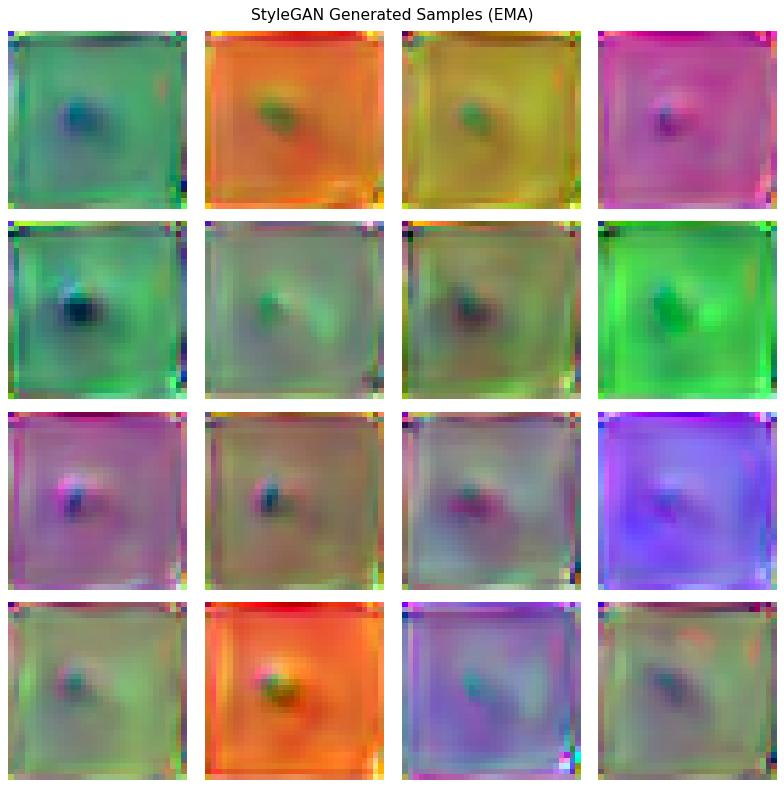

Samples generated.


In [15]:
def denorm(x):
    return (x * 0.5 + 0.5).clamp(0, 1)

ema_G.eval()
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=DEVICE)
    samples = denorm(ema_G(z)).cpu()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img.permute(1, 2, 0))
    ax.axis('off')
plt.suptitle('StyleGAN Generated Samples (EMA)', fontsize=14)
plt.tight_layout()
plt.savefig('generated_samples.png', dpi=100, bbox_inches='tight')
plt.show()
print("Samples generated.")


## 16. Style Mixing Visualization

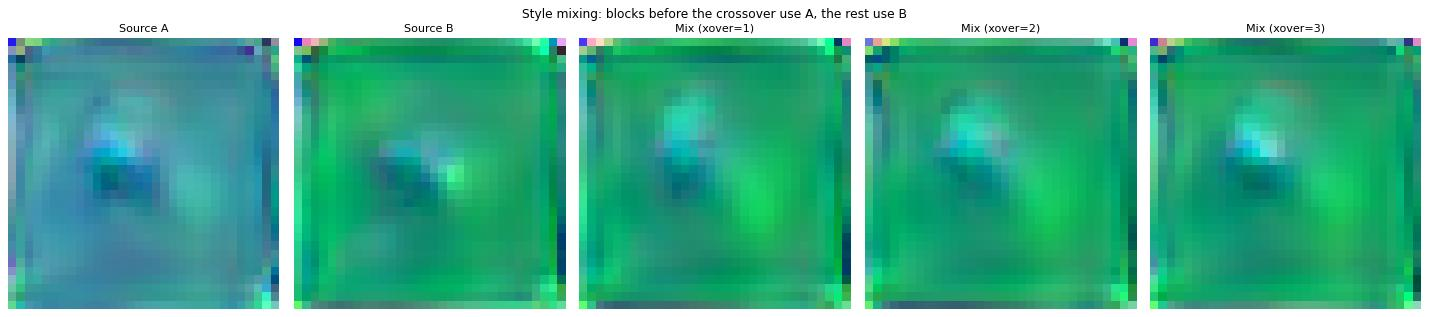

Style mixing saved.


In [16]:
"""Style mixing: use w1 for coarse layers, w2 for fine layers."""
ema_G.eval()
with torch.no_grad():
    z1 = torch.randn(1, LATENT_DIM, device=DEVICE)
    z2 = torch.randn(1, LATENT_DIM, device=DEVICE)
    img_a = denorm(ema_G(z1)).cpu()
    img_b = denorm(ema_G(z2)).cpu()
    mixed_images = [img_a, img_b]
    labels = ['Source A', 'Source B']
    for crossover in range(1, 4):
        mixed = denorm(ema_G(z1, z2, crossover)).cpu()
        mixed_images.append(mixed)
        labels.append(f'Mix (xover={crossover})')

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, img, label in zip(axes, mixed_images, labels):
    ax.imshow(img[0].permute(1, 2, 0))
    ax.set_title(label, fontsize=10)
    ax.axis('off')
plt.suptitle('Style mixing: blocks before the crossover use A, the rest use B', fontsize=11)
plt.tight_layout()
plt.savefig('style_mixing.png', dpi=100, bbox_inches='tight')
plt.show()
print("Style mixing saved.")


## 17. Stochastic Variation

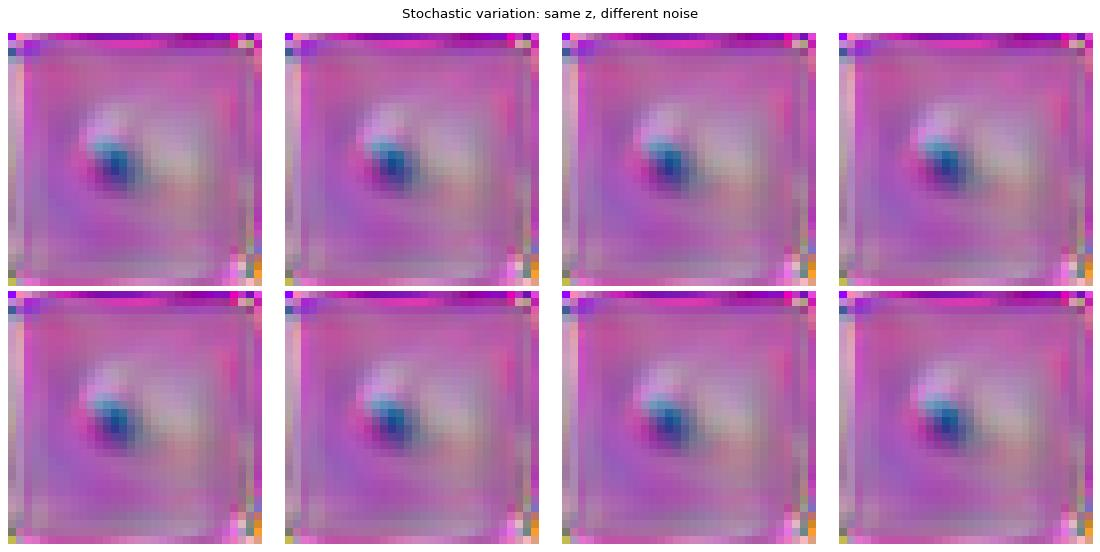

Stochastic variation saved.
Mean absolute pixel difference from the average image: 0.0021 (on the [0, 1] scale)
Mean learned noise weight per layer: min 0.0004, max 0.0032


In [17]:
"""Fix w, vary noise — structure preserved, details vary."""
ema_G.eval()
with torch.no_grad():
    z_fixed = torch.randn(1, LATENT_DIM, device=DEVICE)
    variations = []
    for _ in range(8):
        img = denorm(ema_G(z_fixed)).cpu()
        variations.append(img[0])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img in zip(axes.flat, variations):
    ax.imshow(img.permute(1, 2, 0))
    ax.axis('off')
plt.suptitle('Stochastic variation: same z, different noise', fontsize=12)
plt.tight_layout()
plt.savefig('stochastic_variation.png', dpi=100, bbox_inches='tight')
plt.show()
print("Stochastic variation saved.")

# How much does the noise actually change the image?
stack = torch.stack(variations)
print(f"Mean absolute pixel difference from the average image: {(stack - stack.mean(0)).abs().mean().item():.4f} (on the [0, 1] scale)")
noise_w = [m.weight.abs().mean().item() for m in ema_G.modules() if isinstance(m, NoiseInjection)]
print(f"Mean learned noise weight per layer: min {min(noise_w):.4f}, max {max(noise_w):.4f}")


## 18. Latent Interpolation

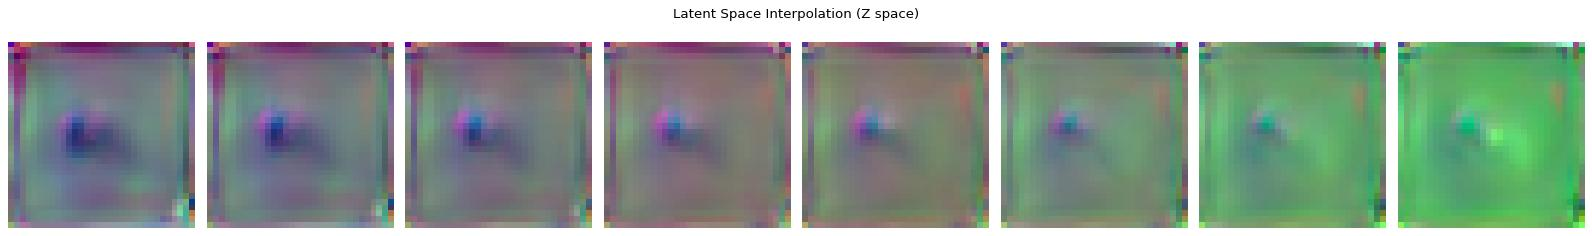

Latent interpolation saved.


In [18]:
"""Interpolate between two latent codes."""
ema_G.eval()
n_steps = 8
with torch.no_grad():
    z_start = torch.randn(1, LATENT_DIM, device=DEVICE)
    z_end = torch.randn(1, LATENT_DIM, device=DEVICE)
    alphas = torch.linspace(0, 1, n_steps, device=DEVICE).unsqueeze(1)
    z_interp = z_start * (1 - alphas) + z_end * alphas
    interp_images = denorm(ema_G(z_interp)).cpu()

fig, axes = plt.subplots(1, n_steps, figsize=(20, 3))
for ax, img in zip(axes, interp_images):
    ax.imshow(img.permute(1, 2, 0))
    ax.axis('off')
plt.suptitle('Latent Space Interpolation (Z space)', fontsize=12)
plt.tight_layout()
plt.savefig('latent_interpolation.png', dpi=100, bbox_inches='tight')
plt.show()
print("Latent interpolation saved.")


## 19. Summary

### What the run above shows

The generator trained for 3,000 steps, but it **learned only part of the data**, and the StyleGAN properties the paper reports do not show up at this scale. GPU runs can differ slightly, so the exact numbers are in the printed outputs above. Where this summary quotes numbers, they come from two earlier runs of the same code (not saved here).

- **Training:** at epoch 1 the mean losses were near their untrained values (about D 1.32 and G 0.68). They then moved away from those values and stayed roughly between 0.8 and 1.4 for the rest of training, with no steady downward trend. In the two earlier runs, the epoch-120 means were D 1.13 / G 1.02 and D 1.32 / G 0.82.
- **Samples:** the generator learned the spread of background colors, but it did not learn clean circles and squares. In the two earlier runs, samples showed either a faint dark blob or a multicolored blob, almost always near the center, instead of one solid shape at a random position. Colored stripes run along the image edges.
- **Style mixing:** the mixed images take most of their look from source B, because even the earliest crossover hands three of the four blocks to B. The run shows no clean split between coarse and fine styles.
- **Noise:** the eight images from one z with different noise look the same. The printed pixel difference and noise weights above are tiny, so this generator learned to almost ignore its noise inputs, unlike the paper's.
- **Interpolation:** moving between two latents changes the color smoothly.

So the notebook shows how the mapping network, AdaIN, the learned constant, noise inputs and style mixing fit together. It does not reproduce the paper's results on disentanglement or scale-specific control, which come from far larger models trained for much longer on FFHQ.


## 20. Cleanup

In [19]:
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Cleanup done. Notebook complete.")


Cleanup done. Notebook complete.
